In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from functools import partial
from scipy.integrate import quad
import warnings
warnings.filterwarnings('ignore')

#plotting parameters
newparams = {'figure.figsize': (8.0, 4.0), 'axes.grid': True,
'lines.markersize': 8, 'lines.linewidth': 2,
'font.size': 8}
plt.rcParams.update(newparams)

### Exercise 1

##### 1a)

We find the time derivative,

$$
\frac{\partial \phi}{\partial t} = \frac{\partial}{\partial t} \left[ \frac{1}{\sqrt{4\pi D t}} \int_{-\infty}^{\infty} dy \, h(y) e^{-\frac{(x-y)^2}{4Dt}} \right]
$$

and get

$$
\frac{\partial \phi}{\partial t} = \int_{-\infty}^{\infty} dy \, h(y) \left( -\frac{1}{2t} + \frac{(x-y)^2}{4Dt^2} \right) \frac{1}{\sqrt{4\pi D t}} e^{-\frac{(x-y)^2}{4Dt}}.
$$

We compute the first derivative of $x$

$$
\frac{\partial}{\partial x} \left[ \frac{1}{\sqrt{4\pi D t}} \int_{-\infty}^{\infty} dy \, h(y) e^{-\frac{(x-y)^2}{4Dt}} \right] =
 -\frac{1}{2Dt} \frac{1}{\sqrt{4\pi Dt}} \int_{-\infty}^{\infty} dy \, h(y) (x - y) e^{-\frac{(x - y)^2}{4Dt}}.
$$

We compute the second derivative of $x$,

$$
D \frac{\partial^2 \phi}{\partial x^2} = \frac{1}{\sqrt{4\pi Dt}} \int_{-\infty}^{\infty} dy \, h(y) e^{-\frac{(x - y)^2}{4Dt}} \left(- \frac{1}{2t} + \frac{(x - y)^2}{4D t^2} \right).
$$

Multiplying by \( D \) and integrating, we obtain

$$
D \frac{\partial^2 \phi}{\partial x^2} = \frac{\partial \phi}{\partial t}.
$$

Thus, $ \phi(x,t) $ satisfies the diffusion equation.

With $\sigma = \sqrt{2Dt}$, we obtain
$$
\phi(x, \sigma) =  \int_{-\infty}^{\infty} dy\, h(y) \frac{1}{\sqrt{2 \pi }\sqrt{\sigma}} e^{-\frac{1}{2}\frac{(x-y)^2}{\sigma ^2}},
$$

which is an integral over Gaussian functions, that are scaled by a the function $h(y)$. 

We consider the limit $ t \to 0 $, and observe $\sigma \to 0$. Since a Gaussian function with stanard deviation $\sigma  = 0$ can be represented as the Dirac Delta-function with parameter $y-x$ and
$$
\lim_{t \to 0} \phi(x,t) = \int_{-\infty}^{\infty} dy \, h(y) \delta(y - x),
$$

which simplifies to

$$
\phi(x,0) = h(x).
$$

This means $ h(y) $ represents the initial distribution of particles along the $ x $-axis at $ t = 0 $.

##### 1b)

We have the proportional relationships:
$$
p^+ \propto P(x_0 + 1), \quad p^- \propto P(x_0 - 1), \quad p^0 \propto P(x_0),
$$
which combined with the definition of probability gives
$$
p^+ = \frac{P(x_0 + 1)}{P(x_0) + P(x_0 + 1) + P(x_0 - 1)},
$$
and similarly for $ p^- $ and $ p^0 $. Substituting in $ P(x) = e^{-\beta V(x)} / Z $, we have
$$
p^+ = \frac{e^{-\beta V(x_0 + 1)}}{e^{-\beta V(x_0)} + e^{-\beta V(x_0 + 1)} + e^{-\beta V(x_0 - 1)}}.
$$
further this simplifies to
$$
p^+ = \frac{1}{1 + e^{-\beta [V(x_0 - 1) - V(x_0 + 1)]} + e^{-\beta [V(x_0) - V(x_0 + 1)]}}.
$$

Similarly for $ p^- $ and $ p^0 $, we get
$$
p^- = \frac{1}{1 + e^{-\beta [V(x_0 + 1) - V(x_0 - 1)]} + e^{-\beta [V(x_0) - V(x_0 - 1)]}},
$$
and
$$
p^0 = \frac{1}{1 + e^{-\beta [V(x_0 + 1) - V(x_0)]} + e^{-\beta [V(x_0 - 1) - V(x_0)]}}.
$$

##### 1c)

I høytemperaturgrensen $k_B T \gg |V(x+1) - V(x)|$ , vil de eksponensielle leddene nærme seg 1. Dermed blir overgangssansynlighetene $p^+$, $p^0$, og $p^-$ all tilnærmet like og nær $1/3$. I dette tildellet dominerer de termiske fluktuasjonene over potensialforskjellene, og bevegelsen kan beksirves som en isotrop, symmetrisk tilfeldig vandring. 


I lavtemperaturgrensen $k_B T \ll |V(x+1) - V(x)|$, blir $\beta$ stor, slik at selv små forskjeller i potensialet får stor betydning. Dette fører til at enten $p^+$ or $p^-$ får mot 1, mens de øvringe overgangssannstnlighetene går mot 0. Partiklene vil da bevege seg i retning av avtagende potensial. 


In the high temperature case, the potential becomes less relevant due to the dominance of the thermal fluctuations, so we can simplify the problem to a symmetrical random walk. In the low temperature case, the particles will always move in the direction of decreasing potential. This means we can make the assumption that eventually all particles will concentrate at the potentials nearest minima.

### Exercise 2

In [22]:
#potential constant set to 1 
k = 1

#potentials in exercise 2
potentialList = [r'$k$',r'-$kx$', r'$k\left(\frac{x}{15} - \cos{\left(\frac{x}{3}\right)} \right)$', r'$kx^4$']

#probability function definitions
def pPlus(V, B, pos):   
    return (1+np.exp(-B*(V(pos-1)-V(pos+1))) + np.exp(-B*(V(pos)-V(pos+1))))**(-1)

def pMin(V, B, pos):
    return (1+np.exp(-B*(V(pos+1)-V(pos-1))) + np.exp(-B*(V(pos)-V(pos-1))))**(-1)


#functions to simulate the random walk 
def simStep(V, B, pos, h, Np):
        p_plus = pPlus(V, B, pos)
        p_min = pMin(V, B, pos)
        sim = np.random.uniform(size = Np)
        pos[sim <= p_min] -= h
        pos[sim > 1-p_plus] += h
        return pos

def simWalk(V, B,  Np = 10000, pos = np.zeros(10000), Tp = 200, dt = 1, h = 1):
    for i in range(int(Tp/dt)):
        pos = simStep(V, B, pos, h, Np)
    return pos


#plotting function for plotting the different values of beta
def simHistogram(V, potential, Beta = np.array([0.01,1,100]), Np = 10000):
    for B in Beta:
        pos = np.zeros(Np)
        pos = simWalk(V, B, Np, pos)
        mu, sigma = norm.fit(pos)
        x = np.linspace(min(pos),max(pos))
        y = norm.pdf(x,mu,sigma)
        plt.hist(pos, bins = 30, label = rf'$\beta k$ = {B}', density=True)
        plt.plot(x,y, label = rf'Fitted normal distribution ($\mu = ${mu:.2f}, $\sigma = $ {sigma:.2f})')
        plt.title(rf"Random walk when $V(x) =$ {potentialList[potential]}")
        plt.xlabel(r"Position after 200 iterations, $x$")
        plt.ylabel(r'Density')
        plt.legend()
        plt.show()

##### 2a)

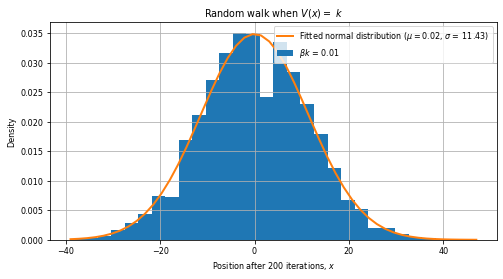

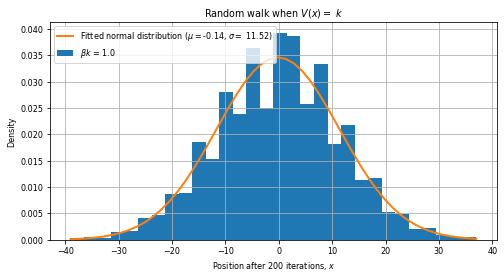

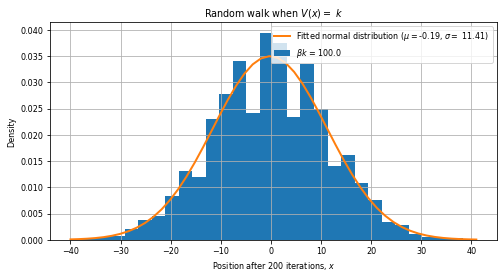

In [23]:
simHistogram(lambda x: k, 0)

From 1a) with initial condition $h(y) =\delta (y)$, the distribution is 

$$
\phi(x,t) = \frac{1}{\sqrt{4 \pi D t}} \exp \left({\frac{-x^2}{4Dt}}\right),
$$

which is a normal distribution with mean $\mu = 0$ and variance $\sigma^2 = 2Dt$. From theory, we obtain 

$$
D = \frac{d h^2}{2 \Delta t} \quad \text{ and } \quad \frac{d}{2} = p^{\pm},
$$

where $h$ is the step size, $\Delta t$ is the time step and $t$ is the parameter $T_p$ from the exercise. We then obtain $\sigma^2 = 2 p^{\pm} T_p$. When $\beta k << |V(x+1)-V(x)|$ we have that $p^{\pm} = \frac{1}{3}$. With $T_p = 200$ the variance $\sigma^2 \approx 133$. For a normal distribution the 95-percentile confidence interval is $\mu \pm z_{0.25} \cdot \sigma$. With $z_{0.25} \approx 2$, about 95% of the data should be within $\pm 2\cdot \sigma \approx \pm 23$, something which seems to be the case for all plots.

The parameter $\beta k$ does not influence the distribution since the potential is constant, and diffusion alone determines the particle spread.


##### 2b)

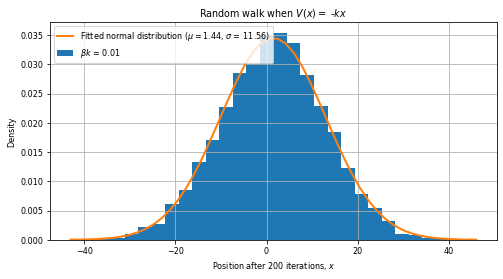

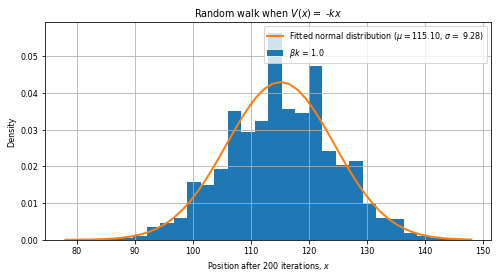

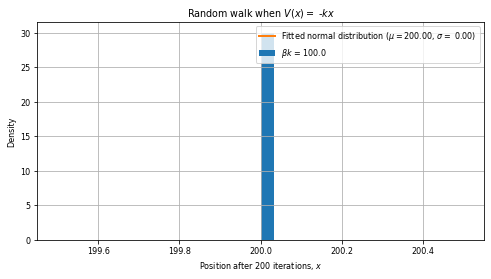

In [24]:
simHistogram(lambda x: -k*x, 1)

For the potential $V(x) = -kx$, the particle distribution changes depending on the value of $\beta k$.  

For $\beta k = 0.01$, the distribution remains nearly symmetric around $x = 0$ with a mean $\mu$ and $\sigma$ approximately close to the particle spread with constant potential. Thermal fluctuations dominate of the potential $V(x)$, which illustrate a behaviour similar to free diffusion.

For $\beta k = 1.0$, the distribution shifts toward positive $x$ values, with a mean of $\mu > 0$ and a smaller standard deviation $\sigma$. Even though the potential favors movement in the positive $x$-direction, diffusion effects are still present.

For $\beta k = 100.0$, the potential completely dominates the thermal fluctuations, resulting in all particles accumulating at $x = 200$. The motion has become completely deterministic rather than diffusive, as illustrated by a mean of $\mu = 200.00$ and a standard deviation of $\sigma = 0.00$.

##### 2c)

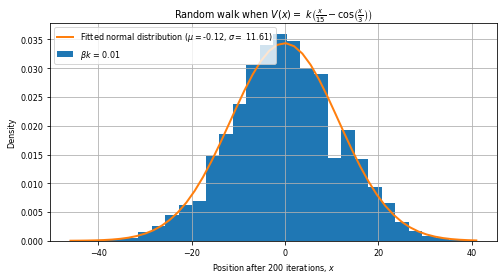

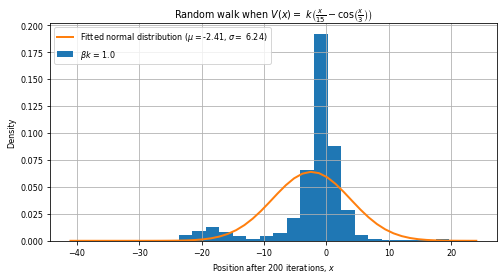

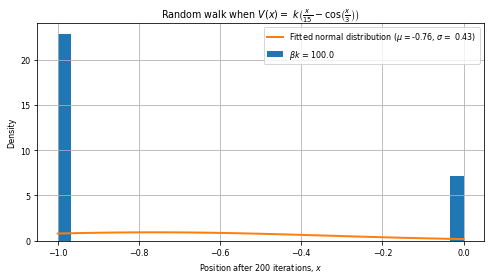

In [25]:
simHistogram(lambda x: k*(x/15-np.cos(x/3)),2)

For $\beta k = 0.01$, the distribution remains nearly normal with a slight asymmetry. This suggests that thermal fluctuations dominate over the potential, allowing free diffusion, with only a minor influence due to the potential. 

For $\beta k = 1.0$, the distribution becomes asymmetric, with a major accumulation of particles near $x = 0$. The term $-\cos(x/3)$ of the potential $V(x)$ creates potential minima, causing particles to settle in these regions (while diffusion effects still are present). In addition, the term depending on $x$ make the particle spread tend to the left.

For $\beta k = 100.0$, the particles are almost entirely localized at -1 and 0. That is because the model operates with a discrete x-axis (with stepsize $h = 1$) and the true minimum is located at $x \approx -0.6$. This illustrates how the particles move from free random motion to being trapped in the potential wells as $\beta k$ increases.

##### Additional task

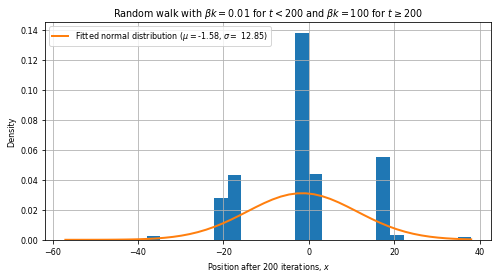

In [26]:
pos = np.zeros(10000)
pos = simWalk(lambda x: k*(x/15-np.cos(x/3)), 0.01, 10000, pos)
pos = simWalk(lambda x: k*(x/15-np.cos(x/3)), 100, 10000, pos)
mu, sigma = norm.fit(pos)
x = np.linspace(min(pos),max(pos))
y = norm.pdf(x,mu,sigma)
plt.hist(pos, bins = 30, density=True)
plt.plot(x,y, label = rf'Fitted normal distribution ($\mu = ${mu:.2f}, $\sigma = $ {sigma:.2f})')
plt.title(rf"Random walk with $\beta k = 0.01$ for $t<200$ and $\beta k = 100$ for $t \geq 200$")
plt.xlabel(r"Position after 200 iterations, $x$")
plt.ylabel(r'Density')
plt.legend()
plt.show()

In the first 200 time steps, with $\beta k = 0.01$, thermal fluctuations dominate, allowing the particles to move freely. As a result, the distribution remains approximately normal, with only minor effects due to the potential $V(x)$.  

In the next 200 time steps, $\beta k$ is increased to $100.0$, making the potential much stronger than the thermal fluctuations. At this stage, the particles become trapped in local minima, as observed earlier.  

The normal distribution disappears because, at high $\beta k$, the particles get trapped in the most stable positions of the potential.

##### 2d)

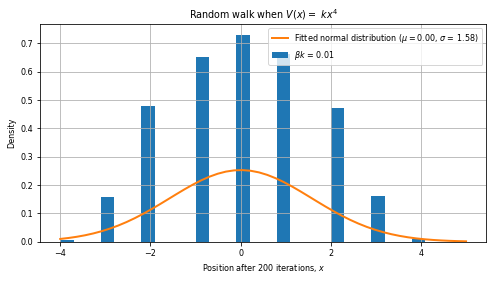

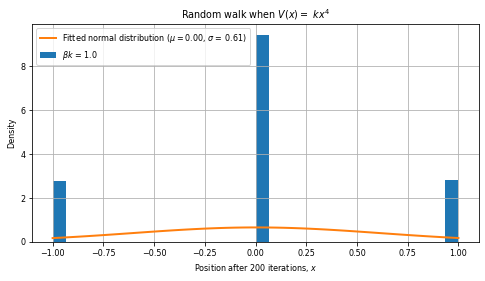

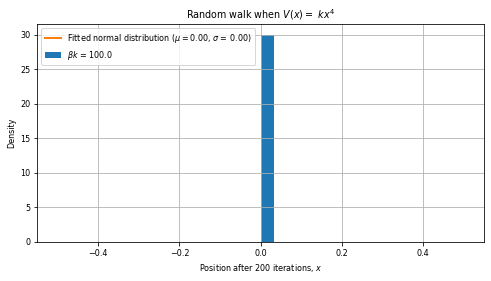

In [27]:
simHistogram(lambda x: k*x**4,3)

The potential $V(x) = kx^4$ creates a symmetric well around $x = 0$. In the quadratic potential, the energy increases as $x^2$, leading to harmonic motion around $x = 0$. In contrast, this quadratic potential creates a steeper and deeper well that strongly confines particles near $x = 0$.  

For small $\beta k$, thermal fluctuations allow particles to explore a wider range of $x$, but they still tend to stay near the center. For larger $\beta k$, the potential dominates, and the particles become increasingly confined. At very high $\beta k$, particles are almost entirely trapped at $x = 0$.  

We have that $k_b T = (\beta)^{-1}$. The plots illustrate that lower temperature and thermal energy is related to the potential energy to dominate. It is also clear that high temperatures tends to dominate and lead to a normal distribution as discussed in 1a). On the other hand, different potentials have different limits for what is a sufficiently low/high temperature. A steep potential as in 2d) will dominate higher temperatures. Likewise, a flat potential as in 2a) is being dominated by lower temperatures. Therefor one must treat the potentials differently. 

### Exercise 3

In [28]:
#potential functions
def V1(x, alpha = 0.1, Nx = 100, k = 1):
    v = np.zeros(len(x))
    x = x%Nx
    cond1 =  ((0 < x) & (x <= alpha*Nx)) 
    v[cond1] = k*x[cond1]/(alpha*Nx)
    cond4 = (alpha*Nx < x) & (x < Nx)
    v[cond4] = -k*(x[cond4]-Nx)/((1-alpha)*Nx)
    return v

def V2(x):
    return k*np.ones(len(x))

##### 3a)

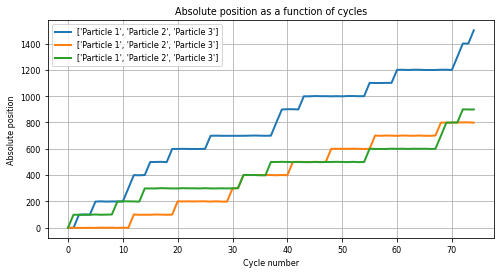

In [29]:
#Random Walk
def randomWalk(Tk, Tp, a, Beta, Np, h = 1, Nx = 100):
    pos = np.zeros(Np, dtype=int)
    abs_pos = np.zeros(Np, dtype=int)
    plot_pos = np.zeros((Tk//(2*Tp), Np))
    V1_alpha = partial(V1, alpha = a)
    for t in range(Tk):
        if t%(2*Tp) < Tp:
            abs_pos = simStep(V2, Beta, abs_pos, h, Np) 
            pos = abs_pos%(2*Nx)
            if t%(2*Tp) == 0:
                plot_pos[t//(2*Tp),:] = abs_pos
        else:            
            abs_pos = simStep(V1_alpha, Beta, abs_pos, h, Np) 
            pos = abs_pos%(2*Nx)
            
    return abs_pos, plot_pos, pos

#variables
abs_pos, plot_pos, pos = randomWalk(30000,200,0.1,1000,3)    
t = np.arange(0,75)

#plotting
plt.plot(t,plot_pos, label = ["Particle 1", "Particle 2","Particle 3"])
plt.xlabel('Cycle number')
plt.ylabel('Absolute position')
plt.title('Absolute position as a function of cycles')
plt.legend()
plt.show()

The plot shows the absolute position of the particles at the end of each cycle, plotted against the cycle number. The random walk behaviour is generated by first simulating $200$ timesteps in a flat potential. This creates a normal distribution with its mean in the starting position as demonstrated in exercise 2a). When shifting to the sawtooth potential, the particles will be dominated by the potential because of the high $\beta k$ value, and therefor "fall" towards one of the minima. Because $\alpha$ is set to $0.1$ the particles that have moved at least $10$ steps right will end the cycle with $+100$ in absolute position. It is very unlikely to move $90$ steps to the right within $200$ timesteps, and therefor the movement appears to have a dircetion and a stairlike pattern.

This shows how the ratchet mechanism works. An asymmetric sawtooth potential and periodic energy create directed motion without an external force. The asymmetry in $V_1(x)$ makes movement easier in one direction, while switching between potentials helps particles cross barriers. This is similar to Brownian ratchets in molecular motors, where random motion and asymmetric energy transfer cause net movement over time.

##### 3b)

In [30]:
#parameters
Nx = 100
distribution = np.sort(np.array(6*list(range(0,2*Nx))))

#calculating current for one timestep
def current(V,B,pos,Np, h=1):
    old_pos = pos.copy()
    pos = simStep(V, B, pos, h, Np)
    move = pos-old_pos
    n_plus = np.sum(move[move == 1])
    n_min = abs(np.sum(move[move == -1]))
    return (n_plus-n_min)/Np
    
#calculating current average for one cycle
def currentAverage(pos, a = 0.8, Tp = 500, Np = 12000, B = 1000):
    Current = []
    V1_alpha = partial(V1, alpha = a)
    for i in range(int(Tp)):
        Current.append(current(V2, B, pos, Np))
    for i in range(int(Tp)):
        Current.append(current(V1_alpha, B, pos, Np))

    Current = np.array(Current)
    currentAverage = np.average(Current)
    return currentAverage

#calculating current average for n cycles
def currentAverageComp(n, a = 0.8, Np = 12000, Nx = 100):

    pos = np.sort(np.array(int(Np/(2*Nx))*list(range(0,2*Nx)))) 
    Averages = []
    for i in range(n):
        Ave = currentAverage(pos, a)
        Averages.append(Ave)
    return Averages


In [31]:
#printing the results
results  = currentAverageComp(10)
print('n \tJavg \n---------------')
print('n \tJavg')
for i in range(10):
    print(f'{i}\t{round(results[i],4)}')

n 	Javg 
---------------
n 	Javg
0	-0.0295
1	-0.0135
2	-0.0132
3	-0.0131
4	-0.0131
5	-0.0132
6	-0.0131
7	-0.0129
8	-0.0134
9	-0.0137


* With $\alpha = 0.8$, particles will tend left rather than right, and one will obtain a negative current, based on the same arguments as in 2d).
* $J_{avg}$ seems to converge towards a value. This is because the particles begins equally spread, but will tend to end in the minima at the end of the cycles. Because the particles will be more equally spread when changing to the sawtooth potential in the first cycle, more will tend to the left than if they are normalized around the minima.

In [32]:
results  = currentAverageComp(10, 0.1)
print('n \tJavg \n--------------')
for i in range(10):
    print(f'{i}\t{round(results[i],4)}')

n 	Javg 
--------------
0	0.0396
1	0.0278
2	0.0279
3	0.028
4	0.0292
5	0.029
6	0.0276
7	0.0276
8	0.0284
9	0.0291


As mentioned, $\alpha \cdot N_x$ is the position of the sawtooth peak. Because the particles will tend to be normal distributed around the minima, the current will be in the direction of the nearest peak. 

When $\alpha < 0.5$ that is to the left and otherwise around for $\alpha > 0.5$.

##### 3c)

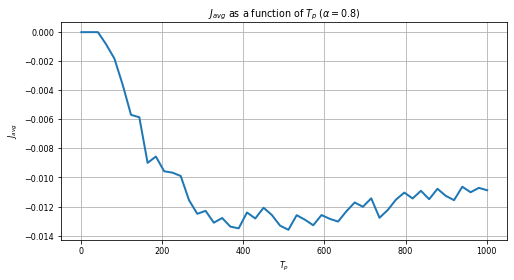

In [33]:
#simulate Javg for different Tp values
def simTpValues(Nx = 100, Tp = np.linspace(1,1001, 50), B = 1000):
    Np = 40*Nx
    tpCurrAv = []
    for t in Tp:
        pos = np.array(int(Np/2)*[0,Nx])
        tpCurrAv.append(currentAverage(pos, 0.8, t, Np, B))
    return Tp, tpCurrAv

#plot
Tp, tpCurrAv = simTpValues()
plt.plot(Tp,tpCurrAv)
plt.xlabel(r'$T_p$')
plt.ylabel(r'$J_{avg}$')
plt.title(r'$J_{avg}$ as a function of $T_p$ $(\alpha = 0.8)$')
plt.show()


For small $T_p$, the particles do not have enough time to diffuse before being trapped by the potential, resulting in little net movement. As $T_p$ increases, diffusion becomes more effective, leading to a stronger net current. However, for very large $T_p$, particles spread too far, reducing the directional transport and causing the current to level off. It appears that the optimum is $T_p \approx 400$.

##### 3d)

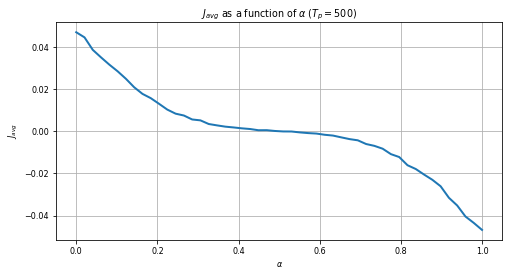

In [34]:
#simulate Javg for different alpha values
def simAlphaValues(Nx = 100, Tp = 500, Np = 4000, B = 1000):
    Np = 40*Nx
    alpha = np.linspace(0,1, 50)
    alphaCurrAv = []
    for a in alpha:
        pos = np.array(int(Np/2)*[0,Nx])
        alphaCurrAv.append(currentAverage(pos, a, Tp, Np, B))
    return alpha, alphaCurrAv

#plot
alpha, alphaCurrAv = simAlphaValues()
plt.plot(alpha, alphaCurrAv)
plt.xlabel(r'$\alpha$')
plt.ylabel(r'$J_{avg}$')
plt.title(r'$J_{avg}$ as a function of $\alpha$ $(T_p = 500)$')
plt.show()

The plot shows that the cycle-averaged current $J_{\text{avg}}$ is positive for small $\alpha$ and becomes negative for large $\alpha$. This confirms that the direction of net particle motion depends on the asymmetry of the potential $V_1(x)$.   

This behavior is explained by how the sawtooth potential influence movement probabilities. When $\alpha < 0.5$, the minima are closer to the right maximum, making rightward motion more frequent. When $\alpha > 0.5$, the asymmetry reverses, favoring motion towards the left. At $\alpha = 0.5$, the potential is symmetric, leading to no preferred direction.

### Exercise 4

In [35]:
#defining integrand
def func(x):
    return np.exp(-x**2)

#calculating analytical current average
def analyticalCurrentAvg(Tp,alpha=0.8,Nx=100):
    z1 = alpha*Nx/2 * np.sqrt(3/Tp)
    z2 = (1-alpha)*Nx/2 * np.sqrt(3/Tp)
    erfc1,error1 = quad(func, z1, np.inf)
    erfc2,error2 = quad(func, z2, np.inf)
    analyticalCurrentAvg = Nx/(4*Tp)*2/np.sqrt(np.pi)*(erfc1-erfc2)
    return analyticalCurrentAvg

##### 4a)

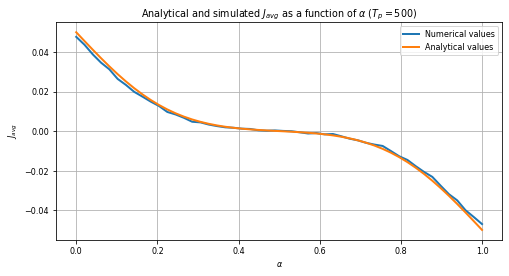

In [36]:
#simulating analytical current averages for different alpha values
def simAnalAlphaVal(Tp = 500, alpha = np.linspace(0,1, 50)):
    AnalAlpha = []
    for a in alpha:
        AnalAlpha.append(analyticalCurrentAvg(Tp,a))
    return AnalAlpha

#plot
alpha, alphaCurrAv = simAlphaValues()
plt.plot(alpha, alphaCurrAv, label = r'Numerical values')
plt.plot(np.linspace(0,1, 50),simAnalAlphaVal(), label = r'Analytical values')
plt.xlabel(r'$\alpha$')
plt.ylabel(r'$J_{avg}$')
plt.title(r'Analytical and simulated $J_{avg}$ as a function of $\alpha$ $(T_p = 500)$')
plt.legend()
plt.show()

The numerical and analytical results for $J_{\text{avg}}(\alpha)$ proves to be almost identical, following the same trend: positive current for small $\alpha$, zero around $\alpha \approx 0.5$, and negative for large $\alpha$. The analytical solution accurately describes the system and confirms that the net current direction is controlled by $\alpha$. The deviation appears to be larger in the limits where $\alpha \to 0$ and $\alpha \to 1$.

##### 4b)

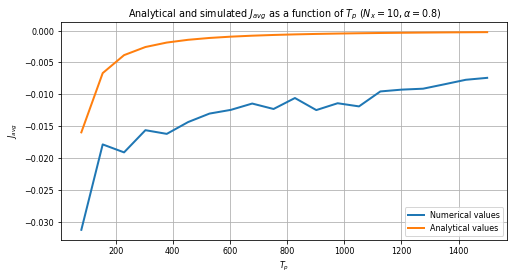

In [37]:
#simulating analytical current averages for different Tp values
def simAnalTpVal(Tp = np.linspace(1,1001,50), Nx = 100):
    AnalCurrAv = []
    for t in Tp:
        AnalCurrAv.append(analyticalCurrentAvg(t, 0.8,Nx))
    return AnalCurrAv

#plot using Nx = 10
Tp, tpCurrAv = simTpValues(10, np.linspace(80,1500,20))
plt.plot(Tp,tpCurrAv, label = 'Numerical values')
plt.plot(Tp,simAnalTpVal(np.linspace(80,1500,20), 10), label = 'Analytical values')
plt.xlabel(r'$T_p$')
plt.ylabel(r'$J_{avg}$')
plt.title(r'Analytical and simulated $J_{avg}$ as a function of $T_p$ $(N_x = 10, \alpha = 0.8)$')
plt.legend()
plt.show()

The plot shows a deviation between the analytical and the numerical results when choosing the parameters as described in the exercise text. Equation 5 from the theory section indicates that a Gaussian diffusion requires $\Delta t$ and $h$ to approach $0$. Since the model is discrete and dimensionless, the ratio $\frac{\Delta t}{T_p}$ and $\frac{h}{N_x}$ needs to be sufficiently low. With $N_x = 100$ (as shown below) the model simulates Gaussian diffusion with significantly lower deviation from the analytical solution. 

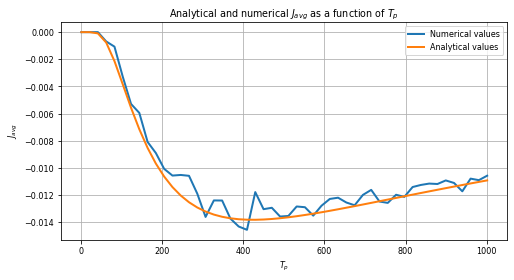

In [38]:
#plot using Nx = 100
Tp, tpCurrAv = simTpValues(100, np.linspace(1,1001,50))
plt.plot(Tp,tpCurrAv, label = r'Numerical values')
plt.plot(Tp,simAnalTpVal(), label = "Analytical values")
plt.xlabel(r'$T_p$')
plt.ylabel(r'$J_{avg}$')
plt.title(r'Analytical and numerical $J_{avg}$ as a function of $T_p$')
plt.legend()
plt.show()

One can observe that the numerical values allign with the analytical result with low deviation when $N_x = 100$. This underlines the hypothesis that the analytical solution requires a sufficiently low ratio $h/N_x$.

##### 4c)

In [39]:
#Different beta values
Beta = np.array([0.01, 1, 2, 3, 5, 10])

#simulating for different beta values
plotB = []
for B in Beta:
    alpha, alphaCurrAv = simAlphaValues(100,500,4000,B)
    plotB.append([alpha, alphaCurrAv, B])

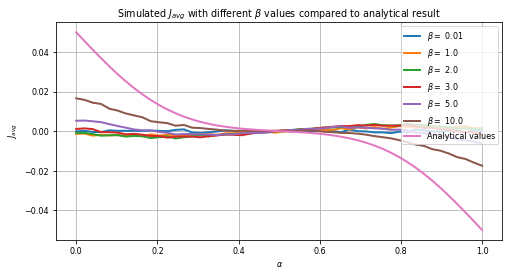

In [40]:
#plot
for pair in plotB:
    plt.plot(pair[0],pair[1], label = fr'$\beta = $ {pair[2]}')
plt.plot(np.linspace(0,1, 50),simAnalAlphaVal(), label = 'Analytical values')
plt.xlabel(r'$\alpha$')
plt.ylabel(r'$J_{avg}$')
plt.title(r'Simulated $J_{avg}$ with different $\beta$ values compared to analytical result')
plt.legend()
plt.show()

The results show that $J_{\text{avg}}$ depends on $\beta k$. For small $\beta k$ (e.g., 0.01, 1, 2, 3), the current stays close to zero for all $\alpha$, meaning thermal fluctuations dominate, and there is no clear net motion. For large $\beta k$ (e.g., 5 and 10), the current follows a clear trend: positive for small $\alpha$, negative for large $\alpha$, and zero around $\alpha \approx 0.5$. This means the potential controls the movement, leading to directed transport.  

These results confirm that the balance between thermal energy and the potential determines whether particles move randomly or in a peferred direction. It also shows that the analytical model assumes that particles will be fully determined by the sawtooth potential.

##### 4d)

There are certain assumptions that challenges the credibility of the "analytical argument". The assumptions of infinitesimal timesteps and step lengths for the diffusion equation makes a significant difference between the two models. For the analytical model we get a continous distribution, while the numerical model follows a discrete distribution. This difference is particularly visible for smaller values of $T_p$ as illustrated in exercise $4b$. Another flaw of small values of $T_p$ is that the particles do not have enough time to diffuse. Our additional plot in Exercise $4b$ also demonstrate the importance of keeping the ratio $\frac{\Delta t}{T_p}$ and $\frac{h}{N_x}$ sufficiently low to avoid large deviations between the analytical and numerical model. Solely based on equation $15$, large values of $N_x/T_p$ in the analytical model predict that the net current approaches zero. This becomes a visible flaw when plotting the numerical model, where the particles spead evenly before interacting with the sawtooth potential, causing the system to reach a steady-state distribution. Larger values for $\beta k$ contribute to the potential dominating the particle movement, but when this is not the case, thermal fluctuations become significant, and particles follow a more random walk in discrete steps. Finally, extreme values of $\alpha$ gives deviations as shown and explained in exercise $4c$. Therefore we can conclude that the analytical model for the cycle-averaged current $J_{\text{avg}}$ works well under certain conditions, but has some weaknesses. These certain conditions are greater values of $T_p$, $\beta k$ and non-extreme values of $\alpha$.